In [57]:
from finguard.data.loader import load_data

In [58]:
df = load_data("../data/raw/creditcard.csv")

Data loaded successfully. Shape: (284807, 31)


In [59]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [60]:
df[["V1", "V2", "V3"]].describe()

,V1,V2,V3
count,2.848070e+05,2.848070e+05,2.848070e+05
mean,1.175161e-15,3.384974e-16,-1.379537e-15
std,1.958696e+00,1.651309e+00,1.516255e+00
min,-5.640751e+01,-7.271573e+01,-4.832559e+01
25%,-9.203734e-01,-5.985499e-01,-8.903648e-01
50%,1.810880e-02,6.548556e-02,1.798463e-01
75%,1.315642e+00,8.037239e-01,1.027196e+00
max,2.454930e+00,2.205773e+01,9.382558e+00


## Class Distribution Analysis

In [61]:
print( f"Total number of transactions: {df.shape[0]}" )

Total number of transactions: 284807


In [62]:
print(df.loc[df["Class"] == 0].value_counts())


Time      V1          V2          V3         V4         V5         V6         V7         V8         V9         V10         V11        V12        V13        V14        V15        V16        V17        V18        V19        V20        V21        V22       V23        V24        V25        V26        V27        V28        Amount  Class
163152.0  -1.196037    1.585949    2.883976   3.378471   1.511706   3.717077   0.585362  -0.156001   0.122648   4.217934    1.385525  -0.709405  -0.256168  -1.564352   1.693218  -0.785210  -0.228008  -0.412833   0.234834   1.375790  -0.370294  0.524395  -0.355170  -0.869790  -0.133198   0.327804  -0.035702  -0.858197  7.56    0        18
          -1.203617    1.574009    2.889277   3.381404   1.538663   3.698747   0.560211  -0.150911   0.124136   4.220998    1.384569  -0.706897  -0.256274  -1.562583   1.692915  -0.787338  -0.226776  -0.412354   0.234322   1.385597  -0.366727  0.522223  -0.357329  -0.870174  -0.134166   0.327019  -0.042648  -0.855262  1.51  

In [63]:
legit_transactions = df.loc[df["Class"] == 0]
fraud_transactions = df.loc[df["Class"] == 1]
print("Number of legitimate transactions:", legit_transactions.shape[0])
print("Number of fraudulent transactions:", fraud_transactions.shape[0])
fraud_percentage = (fraud_transactions.shape[0] / df.shape[0]) * 100
print(f"Percentage of fraudulent transactions: {fraud_percentage:.4f}%")



Number of legitimate transactions: 284315
Number of fraudulent transactions: 492
Percentage of fraudulent transactions: 0.1727%


Dataset Imbalance detected

In [64]:
df.groupby("Class")["Amount"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


## 5. Transaction Amount Analysis

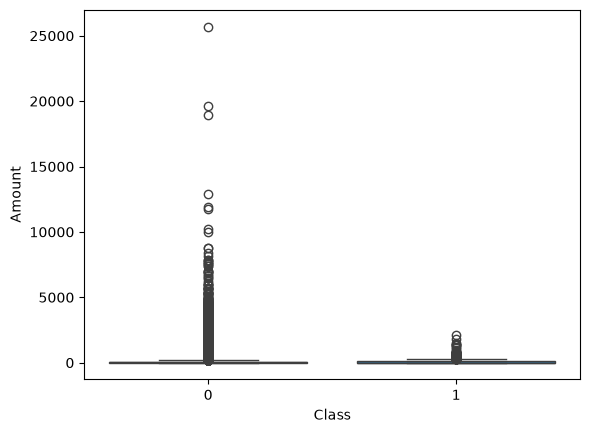

In [65]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(data=df, x="Class", y="Amount")
# plt.yscale("symlog")
plt.show()

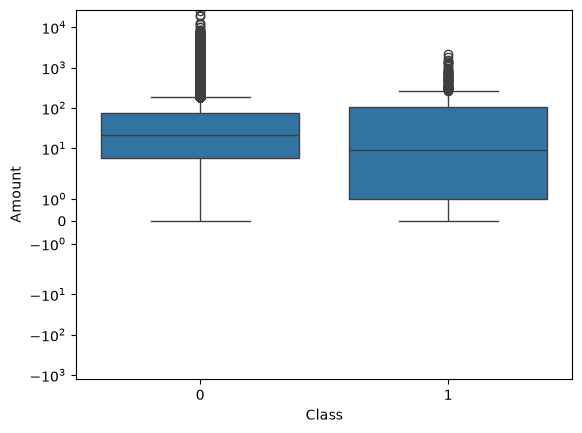

In [66]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(data=df, x="Class", y="Amount")
plt.yscale("symlog")
plt.show()

In [67]:
df.groupby("Class")["Amount"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


## 6. Feature Correlation Analysis

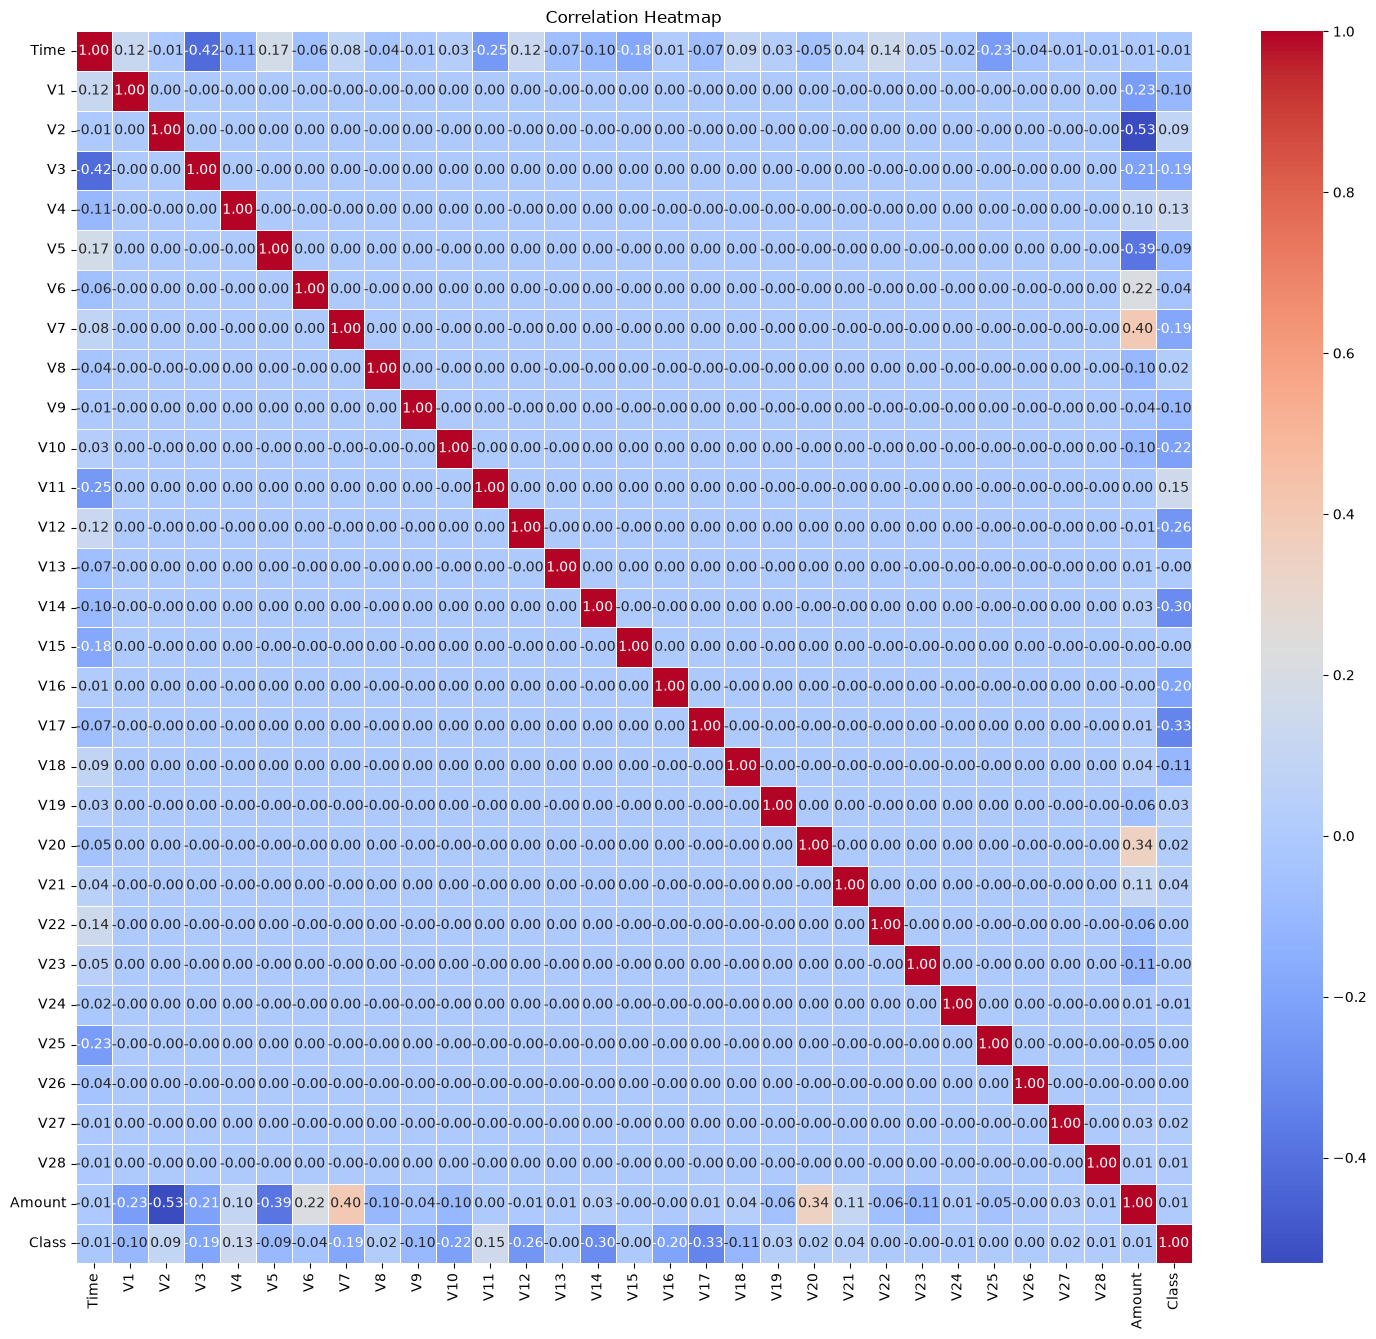

In [68]:
# import matplotlib.pyplot as plt

corr_mat = df.corr()
plt.figure(figsize=(18,16))
sns.heatmap(corr_mat, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

In [69]:
fraud_correlations = corr_mat["Class"].drop("Class").sort_values(ascending=False)
fraud_correlations

V11       0.154876
V4        0.133447
V2        0.091289
V21       0.040413
V19       0.034783
V20       0.020090
V8        0.019875
V27       0.017580
V28       0.009536
Amount    0.005632
V26       0.004455
V25       0.003308
V22       0.000805
V23      -0.002685
V15      -0.004223
V13      -0.004570
V24      -0.007221
Time     -0.012323
V6       -0.043643
V5       -0.094974
V9       -0.097733
V1       -0.101347
V18      -0.111485
V7       -0.187257
V3       -0.192961
V16      -0.196539
V10      -0.216883
V12      -0.260593
V14      -0.302544
V17      -0.326481
Name: Class, dtype: float64

In [70]:
correlations = df.corr()["Class"].drop("Class")

strongest_features = correlations.abs().sort_values(  ascending=False).head(5)

print(strongest_features)

V17    0.326481
V14    0.302544
V12    0.260593
V10    0.216883
V16    0.196539
Name: Class, dtype: float64


###### Here the V17 has a negative correlation as  per the corr ht map , we should analyse V14 as it has a positive corr

In [71]:
top_features = strongest_features.index
fraud_correlations.loc[top_features]

V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
Name: Class, dtype: float64

In [72]:
print(df.groupby("Class")["V17"].describe())

          count      mean       std        min        25%       50%       75%  \
Class                                                                           
0      284315.0  0.011535  0.749457 -17.098444  -0.482644 -0.064833  0.399922   
1         492.0 -6.665836  6.970618 -25.162799 -11.945057 -5.302949 -1.341940   

            max  
Class            
0      9.253526  
1      6.739384  


## 7. V17 Feature Distribution Analysis

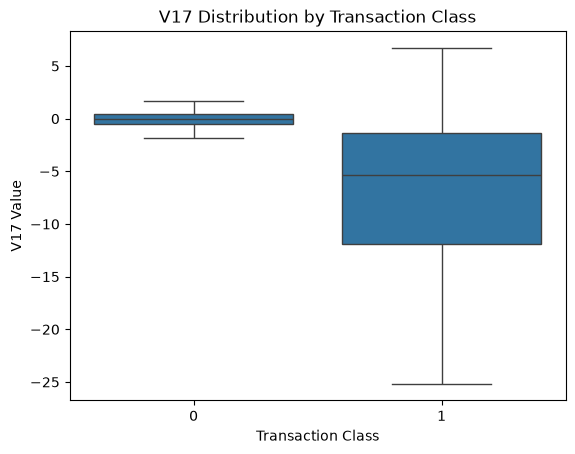

In [73]:
sns.boxplot(data=df, x="Class", y="V17",showfliers=False)

plt.title("V17 Distribution by Transaction Class")
plt.xlabel("Transaction Class")
plt.ylabel("V17 Value")

plt.show()

In [74]:
df.groupby("Class")["V17"].quantile([0.25, 0.75])

Class      
0      0.25    -0.482644
       0.75     0.399922
1      0.25   -11.945057
       0.75    -1.341940
Name: V17, dtype: float64

## 8. V17 Distribution Comparison

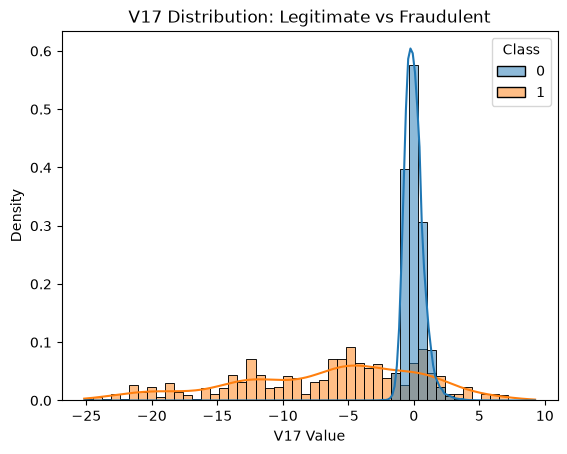

In [75]:
sns.histplot(data=df, x="V17", hue="Class", bins=50, kde=True, stat="density", common_norm=False)
plt.title("V17 Distribution: Legitimate vs Fraudulent")
plt.xlabel("V17 Value")
plt.ylabel("Density")
plt.show()


###### 1. The distributions overlap around zero.
###### 2. strong negative V17 will help in fiding the fraudulent transactions ( -20 -> -5)
###### Therefore, V17 alone cannot perfectly distinguish fraudulent and legitimate transactions.

## 9. V17 Threshold Analysis

In [76]:
# V17_threshold = -5.0
# V17_threshold = -7
V17_threshold = -3

In [77]:
# conditions 
fraud_class = df["Class"] == 1
legit_class = df["Class"] == 0

threshold_less_than_neg5 = df["V17"] < V17_threshold
threshold_greater_than_neg5 = df["V17"] >= V17_threshold

In [78]:
TP = df.loc[fraud_class & threshold_less_than_neg5]
FP = df.loc[legit_class & threshold_less_than_neg5]
TN = df.loc[legit_class & threshold_greater_than_neg5]
FN = df.loc[fraud_class & threshold_greater_than_neg5]


In [79]:
tp = len(TP)
fp = len(FP)
tn = len(TN)
fn = len(FN)

print(f"True Positives (TP): {tp}")
print(f"False Positives (FP): {fp}")
print(f"True Negatives (TN): {tn}")
print(f"False Negatives (FN): {fn}")
print("Total transactions:", tp + fp + tn + fn)

True Positives (TP): 329
False Positives (FP): 98
True Negatives (TN): 284217
False Negatives (FN): 163
Total transactions: 284807


In [80]:
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1_score:.4f}")

Precision: 0.7705
Recall: 0.6687
F1 Score: 0.7160


In [81]:
from sklearn.metrics import precision_score, recall_score, f1_score


y_true = df["Class"]
y_pred = (df["V17"] < V17_threshold).astype(int)

print("Precision:", precision_score(y_true, y_pred))
print("Recall:", recall_score(y_true, y_pred))
print("F1:", f1_score(y_true, y_pred))

Precision: 0.7704918032786885
Recall: 0.6686991869918699
F1: 0.7159956474428727


## Experiment 6: V17 Threshold Comparison

### Objective
Evaluate how changing the V17 classification threshold affects fraud detection performance using Precision, Recall, and F1-score.

### Classification Rules

Two thresholds were evaluated:

- **Threshold 1:** Predict fraud if `V17 < -5`
- **Threshold 2:** Predict fraud if `V17 < -3`

### Experimental Results

| Metric | V17 < -5 | V17 < -3 |
|---|---:|---:|
| Precision | 80.79% | 77.05% |
| Recall | 53.86% | 66.87% |
| F1-score | 64.63% | 71.60% |

### Observations

**1. Precision**

Precision decreased from 80.79% to 77.05%.

This indicates that the proportion of flagged transactions that were actually fraudulent decreased when the threshold changed from -5 to -3.

**2. Recall**

Recall increased from 53.86% to 66.87%.

The new threshold detects a greater proportion of actual fraudulent transactions, reducing the proportion of missed fraud.

**3. F1-score**

The F1-score increased from 64.63% to 71.60%.

This indicates that the -3 threshold achieves a better balance between precision and recall according to the F1 metric.

### Key Findings

- Increasing the V17 threshold from -5 to -3 causes more transactions to be classified as fraudulent.
- This improves fraud detection coverage but also increases the proportion of false alarms among flagged transactions.
- The -3 threshold achieves a higher F1-score than the -5 threshold.
- V17 alone cannot identify every fraudulent transaction because legitimate and fraudulent feature distributions overlap.

### Conclusion

Among the two thresholds evaluated, **V17 < -3 provides better F1-score performance**.

However, these experiments were conducted on data already used during exploratory analysis. Therefore, the results should not be interpreted as unbiased estimates of performance on unseen transactions.

Further evaluation using separate training, validation, and test datasets is required before selecting a final threshold.

### Next Steps

Investigate data quality, preprocessing requirements, and additional features before developing machine learning models.

The eventual classification threshold should be selected using validation data and evaluated against business requirements, including the costs of false positives and false negatives.